# 04 — Global Moran's I

**Question.** Over 2022–2025, are units with many recorded bulletins next to other units with many bulletins
(positive spatial autocorrelation of the per-unit count), for each crime group, on the 2,592 census tracts,
and does the answer depend on the neighbourhood definition?

**Method.** Global Moran's I (Moran 1950) of the per-unit count of bulletins 2022–2025,
$I = \frac{n}{S_0}\frac{\sum_i\sum_j w_{ij} z_i z_j}{\sum_i z_i^2}$, with row-standardised weights.
H0: no spatial autocorrelation. Inference two ways, both reported:
a permutation pseudo p-value (999 permutations, Esri-style default chosen by the project; seed fixed) and
the analytic normality z and two-sided p (`z_norm`, `p_norm`; esda's `Moran` is two-tailed by default).

**Library.** `esda.Moran` (esda 2.6; Rey & Anselin 2007, *PySAL*), weights from `libpysal.weights`:
Queen and Rook contiguity and `KNN` (k = 5 nearest centroids; project choice, compared below with the median
queen neighbour count). Units without a neighbour (islands) are reported and dropped from that run
(`libpysal.weights.w_subset`).

**Citation.** Moran, P.A.P. (1950). Notes on continuous stochastic phenomena. *Biometrika* 37(1/2), 17–23.
Esri, "How Spatial Autocorrelation (Global Moran's I) works" (Esri reports the analytic z; its default
neighbourhood is inverse distance, not contiguity — no numerical parity is claimed).

In [1]:
import time
import warnings

warnings.filterwarnings("ignore", message=".*island.*")
warnings.filterwarnings("ignore", message=".*not fully connected.*")
warnings.filterwarnings("ignore", category=FutureWarning)
import esda
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from libpysal.weights import KNN, Queen, Rook, w_subset

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import SPATIAL_GROUPS as GROUPS
from crime.data import CrimeQuery, Warehouse

SEED = 20221
PERMUTATIONS = 999
K_NN = 5
SUPPORTS = ("tract",)
WEIGHTS = ("queen", "rook", "knn5")
LAB = {"tract": "census tracts"}
OUT = NOTEBOOK_OUTPUTS_DIR / "04_global_moran"
OUT.mkdir(parents=True, exist_ok=True)
T0 = time.time()

## Data and weights

Per-tract counts from the warehouse: `Warehouse.counts(CrimeQuery(crime_group=g))` returns one row per
tract (zero-filled, ordered by tract id, the same order as `Warehouse.census_tracts()`). `unit_id` below is the
census tract id. The KNN graph uses tract centroids (EPSG:31983, metres).

In [2]:
wh = Warehouse()
units = {"tract": wh.census_tracts().rename(columns={"census_tract_id": "unit_id"})}
counts = {("tract", g): wh.counts(CrimeQuery(crime_group=g))["count"].to_numpy(dtype=float) for g in GROUPS}

def build_w(u, kind):
    if kind == "queen":
        w = Queen.from_dataframe(u, ids="unit_id", use_index=False)
    elif kind == "rook":
        w = Rook.from_dataframe(u, ids="unit_id", use_index=False)
    else:
        cent = gpd.GeoDataFrame({"unit_id": u["unit_id"].to_numpy()}, geometry=u.geometry.centroid.to_numpy(), crs=u.crs)
        w = KNN.from_dataframe(cent, k=K_NN, ids="unit_id")
    assert list(w.id_order) == list(u["unit_id"])
    return w

weights, keep = {}, {}
rows = []
for s in SUPPORTS:
    for k in WEIGHTS:
        w = build_w(units[s], k)
        isl = list(w.islands)
        mask = ~units[s]["unit_id"].isin(isl).to_numpy()
        if isl:
            w = w_subset(w, list(units[s]["unit_id"][mask]))
        weights[s, k], keep[s, k] = w, mask
        card = np.array(list(w.cardinalities.values()))
        rows.append(dict(support=s, weights=k, n_units=len(units[s]), n_islands=len(isl), islands="; ".join(map(str, isl)),
                         n_components_after_drop=w.n_components, mean_neighbours=card.mean(), median_neighbours=np.median(card),
                         min_neighbours=card.min(), max_neighbours=card.max()))
wtab = pd.DataFrame(rows)
wtab.to_csv(OUT / "weights_summary.csv", index=False)
wtab

,support,weights,n_units,n_islands,islands,n_components_after_drop,mean_neighbours,median_neighbours,min_neighbours,max_neighbours
0,tract,queen,2592,0,,1,6.030864,5.0,1,38
1,tract,rook,2592,0,,1,5.515432,5.0,1,36
2,tract,knn5,2592,0,,2,5.000000,5.0,5,5


## Moran's I for every group × support × weights

`esda.Moran(y, w, transformation="r", permutations=999)`; `np.random.seed(SEED)` before each call
(esda's global Moran draws from NumPy's global generator).

In [3]:
rows = []
for s in SUPPORTS:
    for g in GROUPS:
        for k in WEIGHTS:
            y = counts[s, g][keep[s, k]]
            np.random.seed(SEED)
            mi = esda.Moran(y, weights[s, k], transformation="r", permutations=PERMUTATIONS)
            rows.append(dict(support=s, group=g, weights=k, n=len(y), events=int(y.sum()),
                             I=mi.I, EI=mi.EI, z_norm=mi.z_norm, p_norm_two_sided=mi.p_norm,
                             z_sim=mi.z_sim, p_sim=mi.p_sim))
moran = pd.DataFrame(rows)
moran.to_csv(OUT / "global_moran.csv", index=False)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")
moran

,support,group,weights,n,events,I,EI,z_norm,p_norm_two_sided,z_sim,p_sim
0,tract,all,queen,2592,107859,0.3759,-0.000386,31.57,8.847e-219,32,0.001
1,tract,all,rook,2592,107859,0.3912,-0.000386,31.58,6.852e-219,31.75,0.001
2,tract,all,knn5,2592,107859,0.2975,-0.000386,25.49,2.767e-143,26.04,0.001
3,tract,property,queen,2592,90436,0.3979,-0.000386,33.42,6.596e-245,33.96,0.001
4,tract,property,rook,2592,90436,0.4133,-0.000386,33.36,4.713e-244,33.76,0.001
5,tract,property,knn5,2592,90436,0.3158,-0.000386,27.05,4.066e-161,27.74,0.001
6,tract,bodily_harm,queen,2592,6590,0.1301,-0.000386,10.95,6.766e-28,10.95,0.001
7,tract,bodily_harm,rook,2592,6590,0.1415,-0.000386,11.44,2.69e-30,11.14,0.001
8,tract,bodily_harm,knn5,2592,6590,0.09419,-0.000386,8.091,5.917e-16,8.07,0.001
9,tract,traffic,queen,2592,6302,0.1149,-0.000386,9.672,3.951e-22,9.741,0.001


In [4]:
wide = moran.pivot_table(index="group", columns=["support", "weights"], values="I").reindex(list(GROUPS))
wide.to_csv(OUT / "global_moran_I_wide.csv")
print("Moran's I of the 2022-2025 bulletin count per unit (rows: group; columns: support x weights)")
wide.round(3)

Moran's I of the 2022-2025 bulletin count per unit (rows: group; columns: support x weights)


support     tract            
weights      knn5 queen  rook
group                        
all         0.298 0.376 0.391
property    0.316 0.398 0.413
bodily_harm 0.094  0.13 0.141
traffic     0.042 0.115 0.115
drug        0.149 0.183 0.193
violent     0.083 0.112 0.111

## Moran scatterplot: all groups, census tracts, queen

x = the unit's count standardised to mean 0, sd 1 (z-score of bulletins 2022–2025); y = the row-standardised
spatial lag of that z (mean z of the queen neighbours). The OLS slope of y on x equals Moran's I
(Anselin 1996, "The Moran scatterplot as an ESDA tool", in *Spatial Analytical Perspectives on GIS*).
Drawn with plain matplotlib; the lag comes from `libpysal.weights.lag_spatial`.

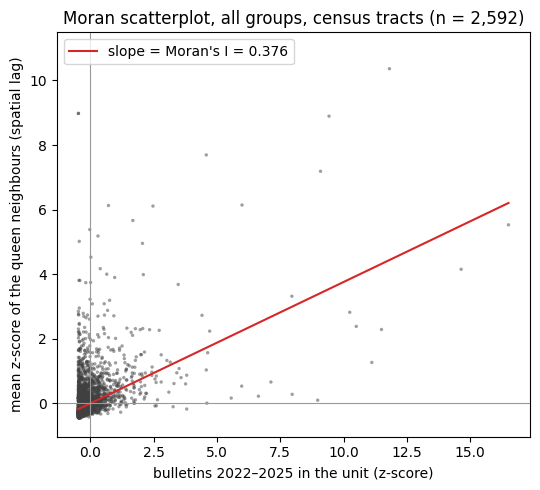

In [5]:
from libpysal.weights import lag_spatial

fig, axes = plt.subplots(1, len(SUPPORTS), figsize=(5.5 * len(SUPPORTS), 5), squeeze=False)
axes = axes[0]
scatter_rows = []
for ax, s in zip(axes, SUPPORTS):
    w = weights[s, "queen"]; w.transform = "r"
    y = counts[s, "all"][keep[s, "queen"]]
    z = (y - y.mean()) / y.std()
    lz = lag_spatial(w, z)
    scatter_rows.append(pd.DataFrame({"support": s, "unit_id": np.asarray(w.id_order), "count": y, "z": z, "lag_z": lz}))
    I = moran.query("support == @s and group == 'all' and weights == 'queen'")["I"].item()
    ax.scatter(z, lz, s=6 if s == "tract" else 18, alpha=0.5, color="0.25", edgecolor="none")
    xs = np.linspace(z.min(), z.max(), 10)
    ax.plot(xs, I * xs, color="C3", lw=1.5, label=f"slope = Moran's I = {I:.3f}")
    ax.axhline(0, color="0.6", lw=0.8); ax.axvline(0, color="0.6", lw=0.8)
    ax.set_xlabel("bulletins 2022–2025 in the unit (z-score)")
    ax.set_ylabel("mean z-score of the queen neighbours (spatial lag)")
    ax.set_title(f"Moran scatterplot, all groups, {LAB[s]} (n = {len(y):,})")
    ax.legend(loc="upper left")
pd.concat(scatter_rows).to_csv(OUT / "moran_scatter_all_queen.csv", index=False)
fig.tight_layout()
fig.savefig(OUT / "moran_scatter_all_queen.png", dpi=300)
plt.show(); plt.close(fig)

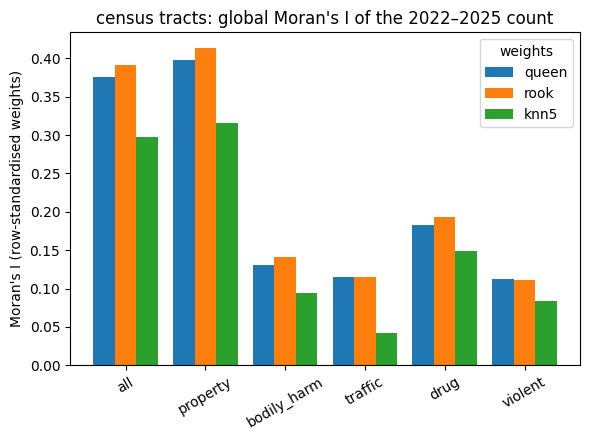

runtime 3 s


In [6]:
fig, axes = plt.subplots(1, len(SUPPORTS), figsize=(6 * len(SUPPORTS), 4.5), sharey=True, squeeze=False)
axes = axes[0]
for ax, s in zip(axes, SUPPORTS):
    sub = moran[moran.support == s]
    xpos = np.arange(len(GROUPS))
    for j, k in enumerate(WEIGHTS):
        v = sub[sub.weights == k].set_index("group").reindex(list(GROUPS))
        ax.bar(xpos + (j - 1) * 0.27, v["I"], width=0.27, label=k)
        for x, (i_, p) in zip(xpos + (j - 1) * 0.27, zip(v["I"], v["p_sim"])):
            if p > 0.05:
                ax.text(x, i_, "ns", ha="center", va="bottom", fontsize=7)
    ax.set_xticks(xpos, GROUPS, rotation=30)
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_title(f"{LAB[s]}: global Moran's I of the 2022–2025 count")
    ax.set_ylabel("Moran's I (row-standardised weights)")
axes[0].legend(title="weights")
fig.tight_layout(); fig.savefig(OUT / "moran_I_by_group.png", dpi=300)
plt.show(); plt.close(fig)
print(f"runtime {time.time() - T0:.0f} s")

In [7]:
# numbers quoted in the Findings cell
print(wtab[["support", "weights", "n_islands", "islands", "n_components_after_drop", "median_neighbours"]].to_string(index=False))
print(moran.assign(sig_perm=moran.p_sim <= 0.05, sig_norm=moran.p_norm_two_sided <= 0.05)
      .groupby("support")[["sig_perm", "sig_norm"]].sum())
print(moran.groupby(["support"])["I"].agg(["min", "max"]))
print(moran.loc[moran.p_sim > 0.05, ["support", "group", "weights", "I", "p_sim", "p_norm_two_sided"]].to_string(index=False))

support weights  n_islands islands  n_components_after_drop  median_neighbours
  tract   queen          0                                1                  5
  tract    rook          0                                1                  5
  tract    knn5          0                                2                  5
         sig_perm  sig_norm
support                    
tract          18        18
            min    max
support               
tract   0.04159 0.4133
Empty DataFrame
Columns: [support, group, weights, I, p_sim, p_norm_two_sided]
Index: []


## Findings

*All numbers are from the cells above (seed 20221, 999 permutations); CSVs in `outputs/nb/04_global_moran/`.*

- **Weights.** Queen gives tracts a mean of 6.03 neighbours (median 5) and rook 5.52 (median 5), so k = 5
  for KNN matches the median queen neighbour count. No tract is an island under any weights; the KNN-5 tract
  graph has 2 disconnected components.
- **All 18 runs (6 groups, 3 weights) show positive spatial autocorrelation.** Permutation p = 0.001, the floor
  for 999 permutations, in 17 runs and 0.003 in the other; the analytic two-sided p is below 0.05 in every run.
- **All groups:** I = 0.376 (queen), 0.391 (rook) and 0.298 (KNN-5). Property (90,436 of 107,859 bulletins)
  drives the total and has almost the same I (0.398 queen).
- **The sparse groups are much weaker.** Bodily harm, traffic, drug and violent have I = 0.04 to 0.19.
- **KNN-5 lowers I for every group** (traffic: 0.115 queen, 0.042 KNN-5), so contiguity and distance-based
  neighbourhoods are not interchangeable at the tract scale.
- **Caveat.** The counts are very skewed (the Moran scatterplot has tracts at z ≈ 16); a global I on raw counts
  is sensitive to a handful of very large tracts and to tract size (no rate or exposure adjustment).
